In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

import sys
import os
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(parent_dir)

from functions.read_g4bl_data import readTraceData, readDetData
from functions.set_plot_settings import setPlotSettings

setPlotSettings(font=True)

## Average of large distribution

sigmas determined by 6d spread of final beam exiting channel in 1000-event stochastics-enabled pencil-beam simulation

beam gaussian particle=mu+ nEvents=1000 \
beamZ=500.0 beamX=$X beamY=$Y beamXp=$Xp beamYp=$Yp \ 
sigmaX=10.0 sigmaY=10.0 sigmaZ=0.0 sigmaXp=0.1 sigmaYp=0.1 \ 
meanMomentum=$p sigmaP=10.0 meanT=0.0 sigmaT=0.1

^ may not be the most representative beam size

--> TODO: try using sigmas from "realistic front-end" beam used for testing baseline design

In [2]:
data = readDetData('zntuple_avg1.txt')

In [6]:
data_start = data[data['z']==500]
data_ref = data[data['EventID']==-1]

In [7]:
x0 = data_start['x'].mean(); print('average x0: '+str(x0))
y0 = data_start['y'].mean(); print('average y0: '+str(y0))
xp0 = data_start['xp'].mean(); print('average xp0: '+str(xp0))
yp0 = data_start['yp'].mean(); print('average yp0: '+str(yp0))
p0 = data_start['ptotal'].mean(); print('average p0: '+str(p0))
t0 = data_start['t'].mean(); print('average t0: '+str(t0))

average x0: 9.91782273036963
average y0: 15.596720602187812
average xp0: 0.06689560651644771
average yp0: -0.03670911943095136
average p0: 200.30423895641164
average t0: -0.006500556911088911


In [8]:
xs = []; ys = []
for z in np.unique(data['z'].values):
    datalim = data[data['z'] == z]
    x = datalim['x'].mean(); xs.append(x)
    y = datalim['y'].mean(); ys.append(y)

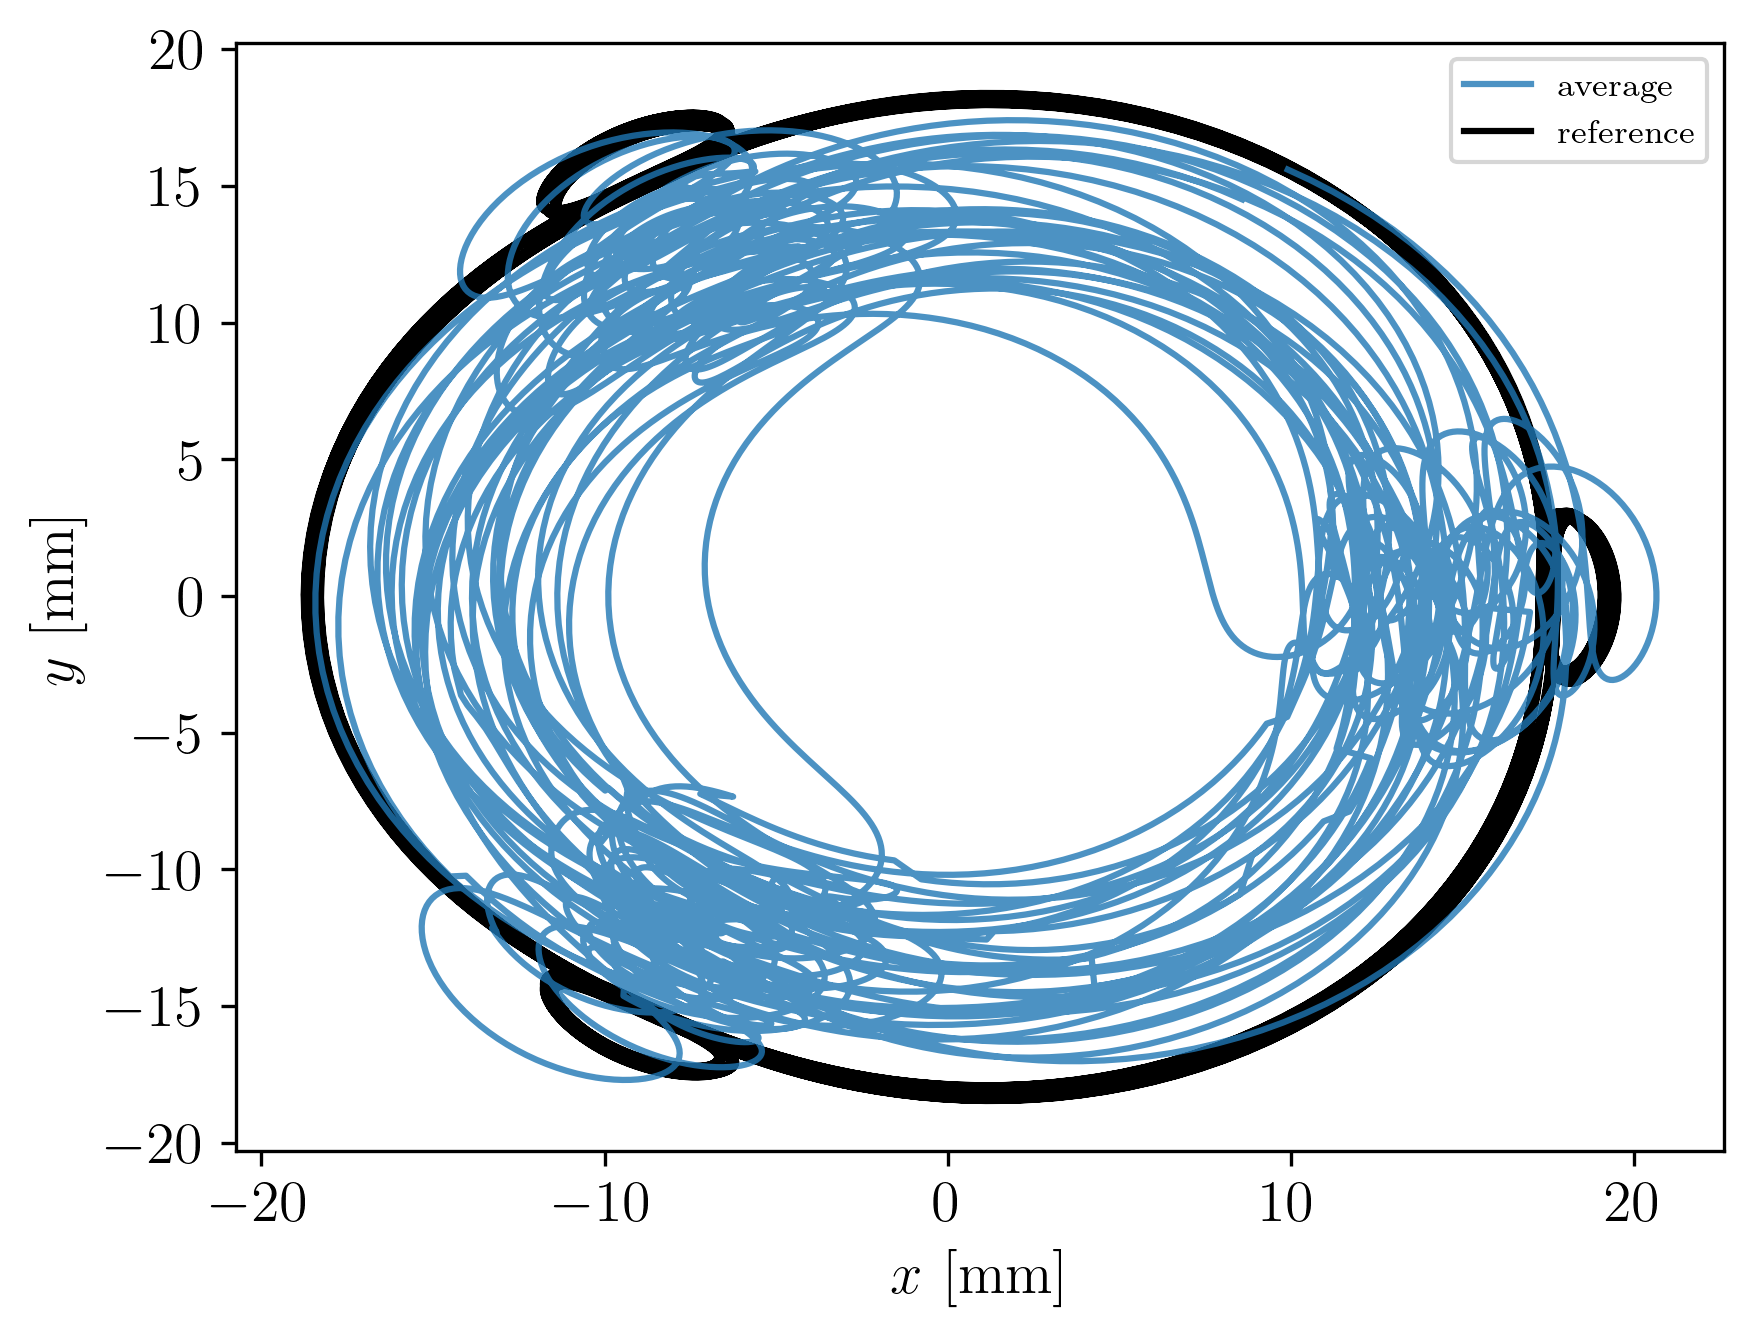

In [10]:
plt.plot(xs, ys, alpha=0.8, label='average')
plt.plot(data_ref['x'].values,data_ref['y'].values,color='black',label='reference', zorder=0)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper right', fontsize=8);

### Single track w/ i.c. of average

In [11]:
data2 = readDetData('zntuple_avg2.txt')

In [12]:
data2 = data2[data2['EventID']==1]

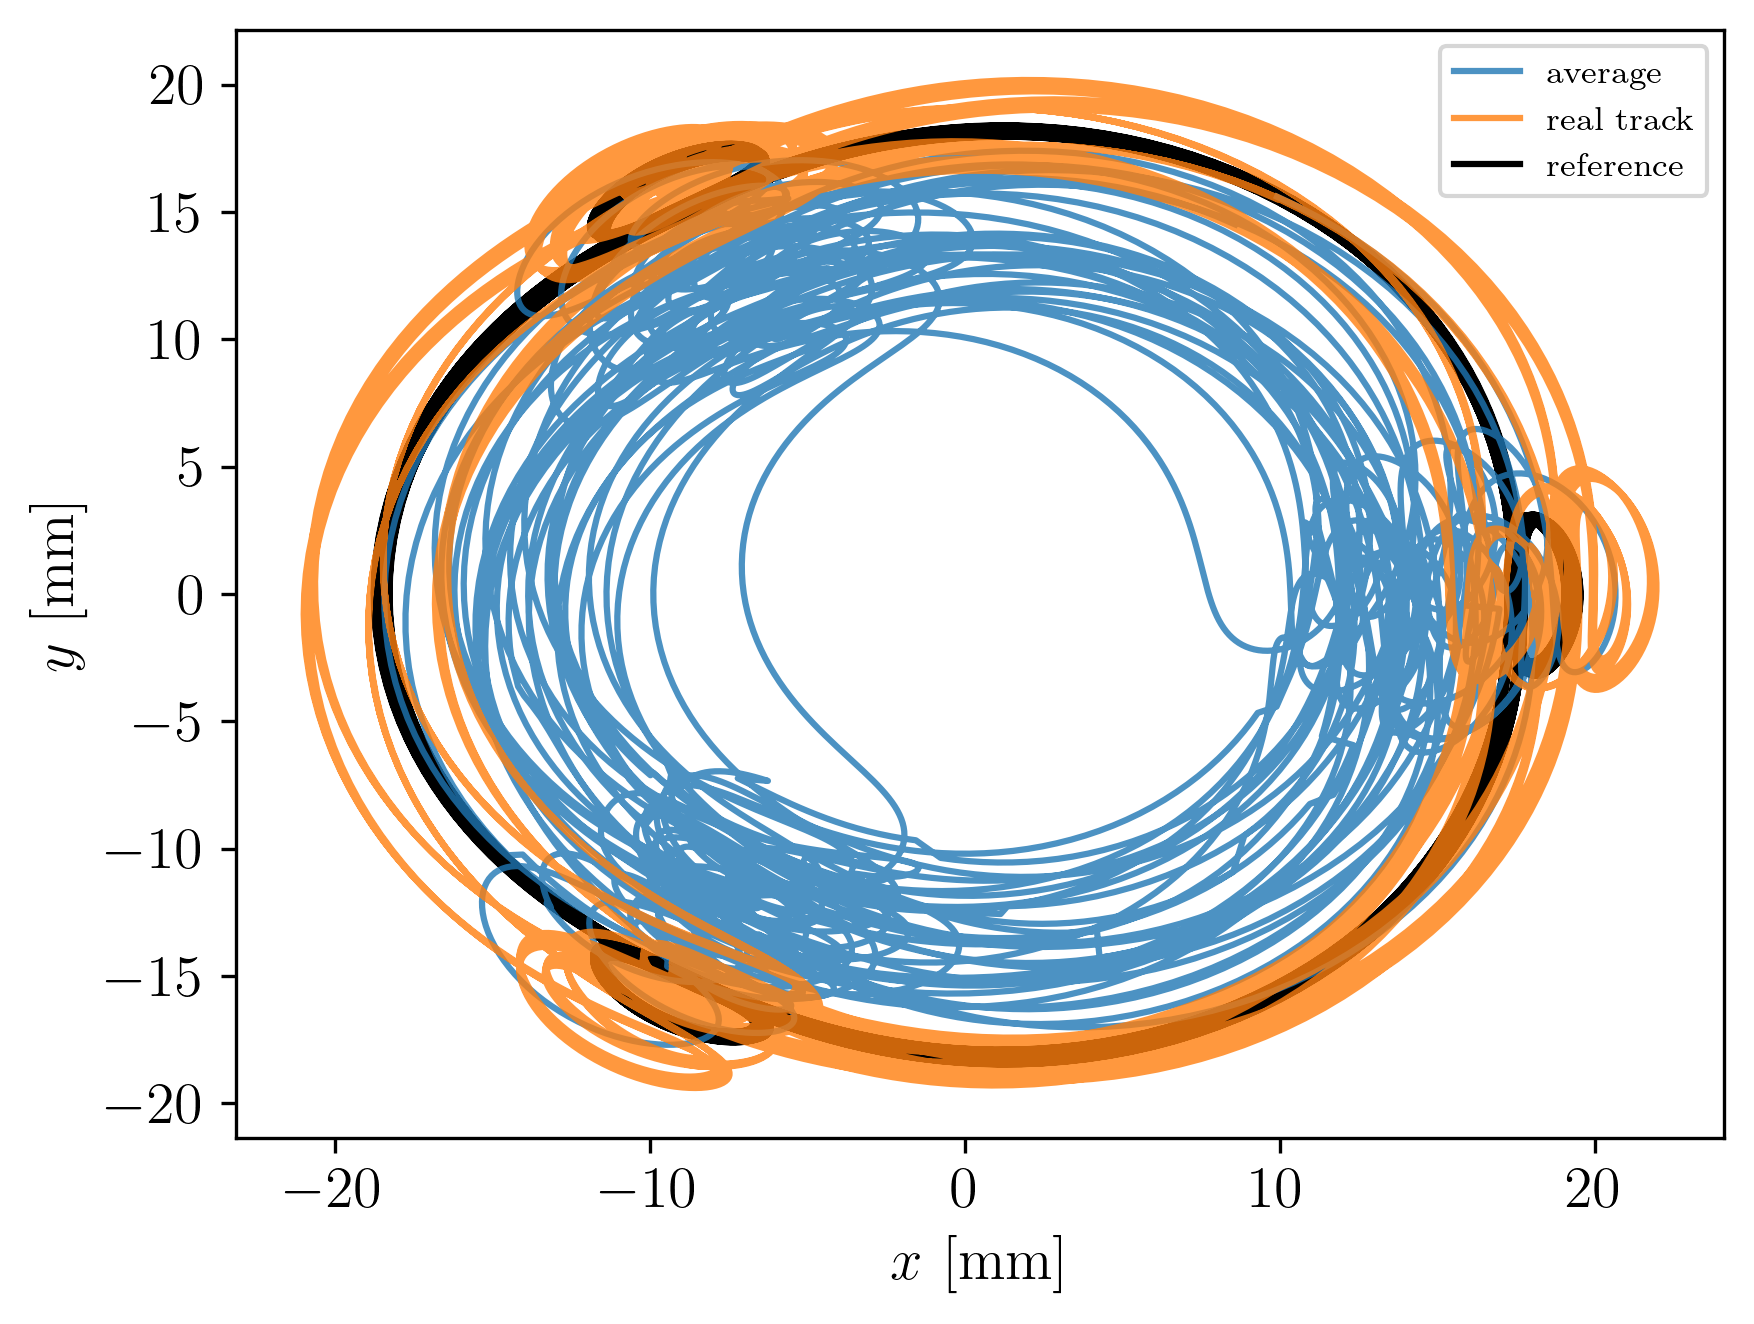

In [13]:
plt.plot(xs, ys, alpha=0.8, label='average')
plt.plot(data2['x'], data2['y'], alpha=0.8, label='real track')
plt.plot(data_ref['x'].values,data_ref['y'].values,color='black',label='reference', zorder=0)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper right', fontsize=8);

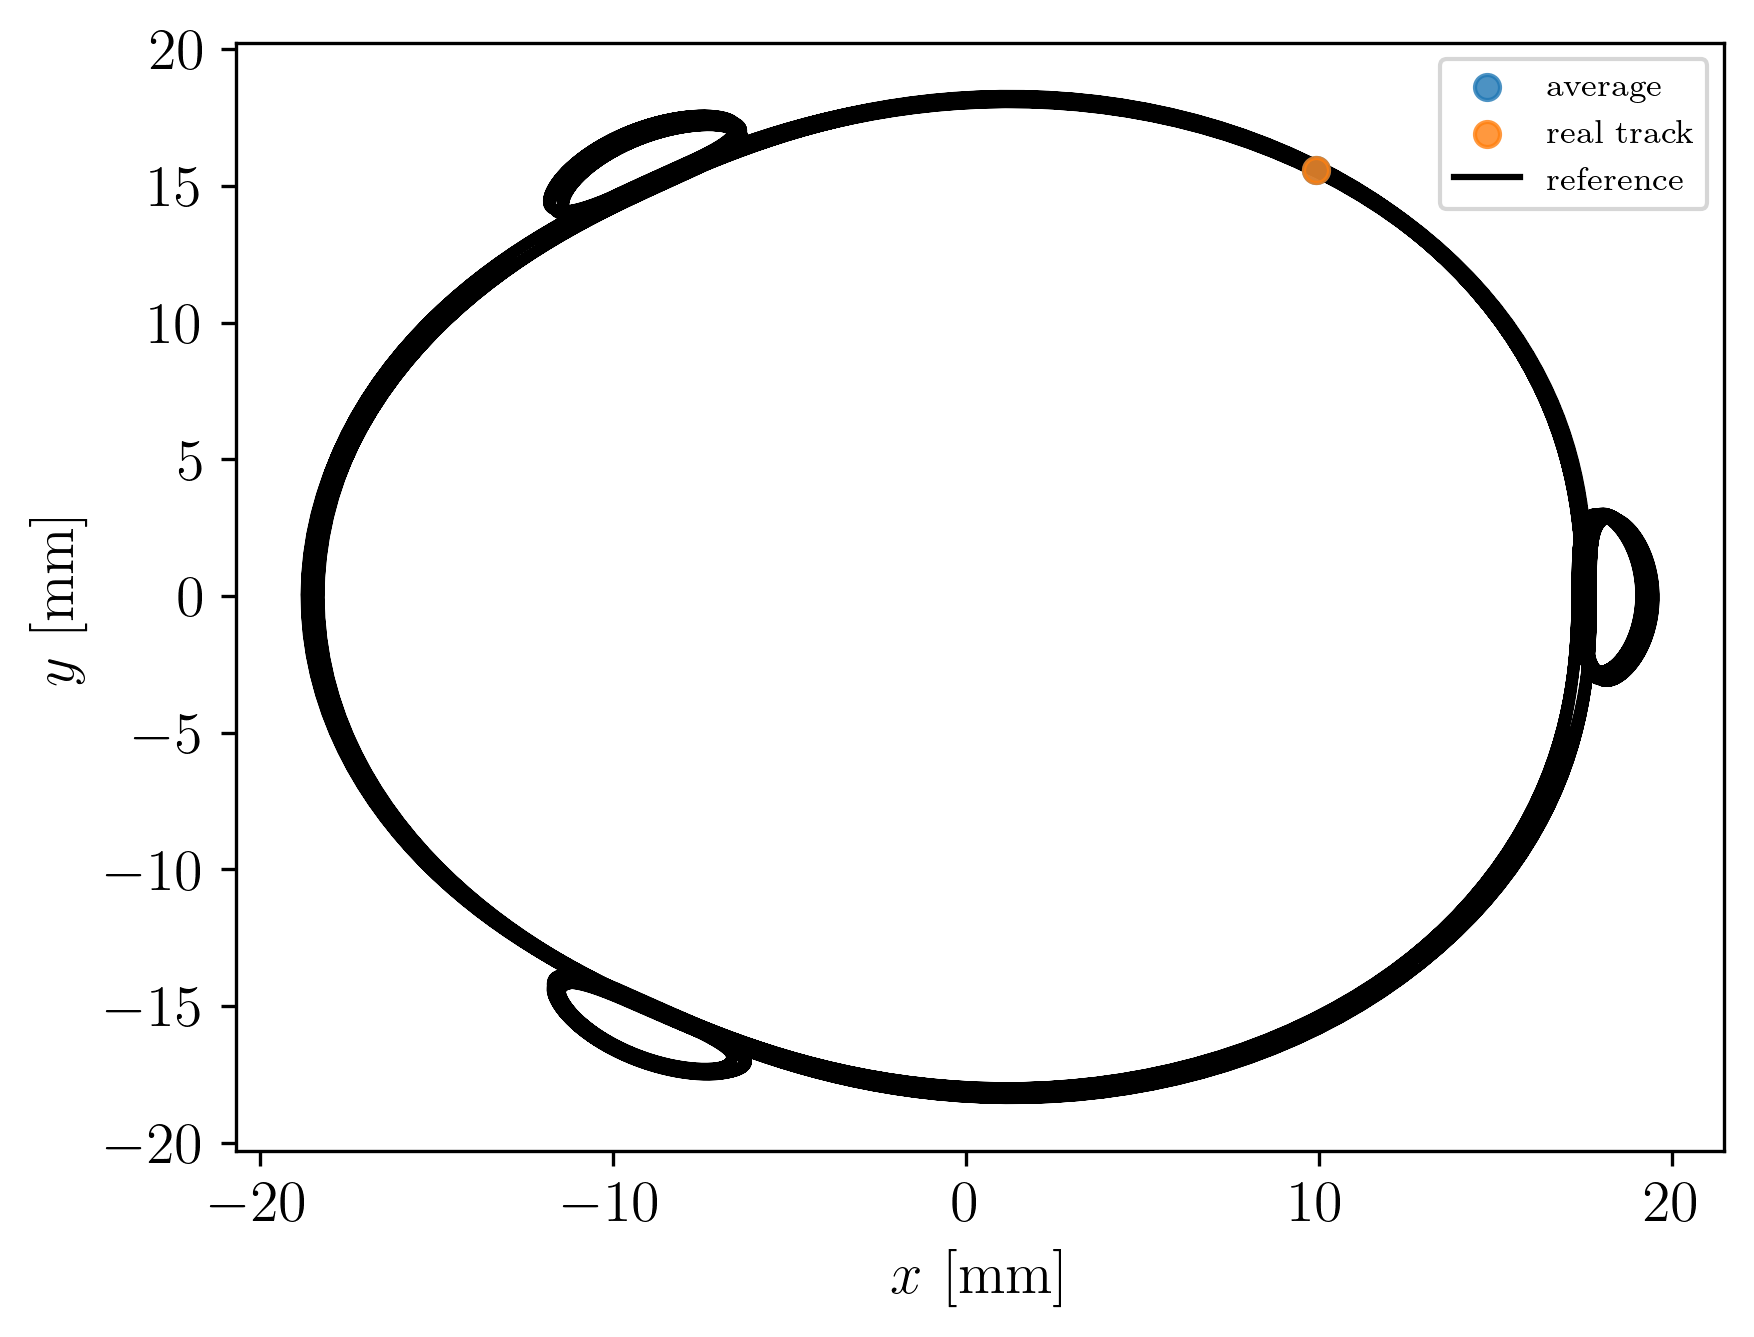

In [15]:
plt.scatter(xs[0], ys[0], alpha=0.8, label='average')
plt.scatter(data2['x'].values[0], data2['y'].values[0], alpha=0.8, label='real track')
plt.plot(data_ref['x'].values,data_ref['y'].values,color='black',label='reference', zorder=0)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper right', fontsize=8);

## Average of small distribution

reduce all sigmas by an order of magnitude

beam gaussian particle=mu+ nEvents=1000 \
beamZ=500.0 beamX=$X beamY=$Y beamXp=$Xp beamYp=$Yp \ 
sigmaX=1.0 sigmaY=1.0 sigmaZ=0.0 sigmaXp=0.01 sigmaYp=0.01 \ 
meanMomentum=$p sigmaP=1.0 meanT=0.0 sigmaT=0.01

In [16]:
data3 = readDetData('zntuple_avg1_2.txt')

In [17]:
data_start3 = data3[data3['z']==500]
data_ref3 = data3[data3['EventID']==-1]

In [18]:
x03 = data_start3['x'].mean(); print('average x0: '+str(x03))
y03 = data_start3['y'].mean(); print('average y0: '+str(y03))
xp03 = data_start3['xp'].mean(); print('average xp0: '+str(xp03))
yp03 = data_start3['yp'].mean(); print('average yp0: '+str(yp03))
p03 = data_start3['ptotal'].mean(); print('average p0: '+str(p03))
t03 = data_start3['t'].mean(); print('average t0: '+str(t03))

average x0: 9.523367982017984
average y0: 16.030861738261738
average xp0: 0.06441825310768562
average yp0: -0.037195913963255924
average p0: 200.03042154038738
average t0: -0.0006500556911088911


In [ ]:
xs3 = []; ys3 = []
for z in np.unique(data3['z'].values):
    datalim3 = data3[data3['z'] == z]
    x3 = datalim3['x'].mean(); xs3.append(x3)
    y3 = datalim3['y'].mean(); ys3.append(y3)

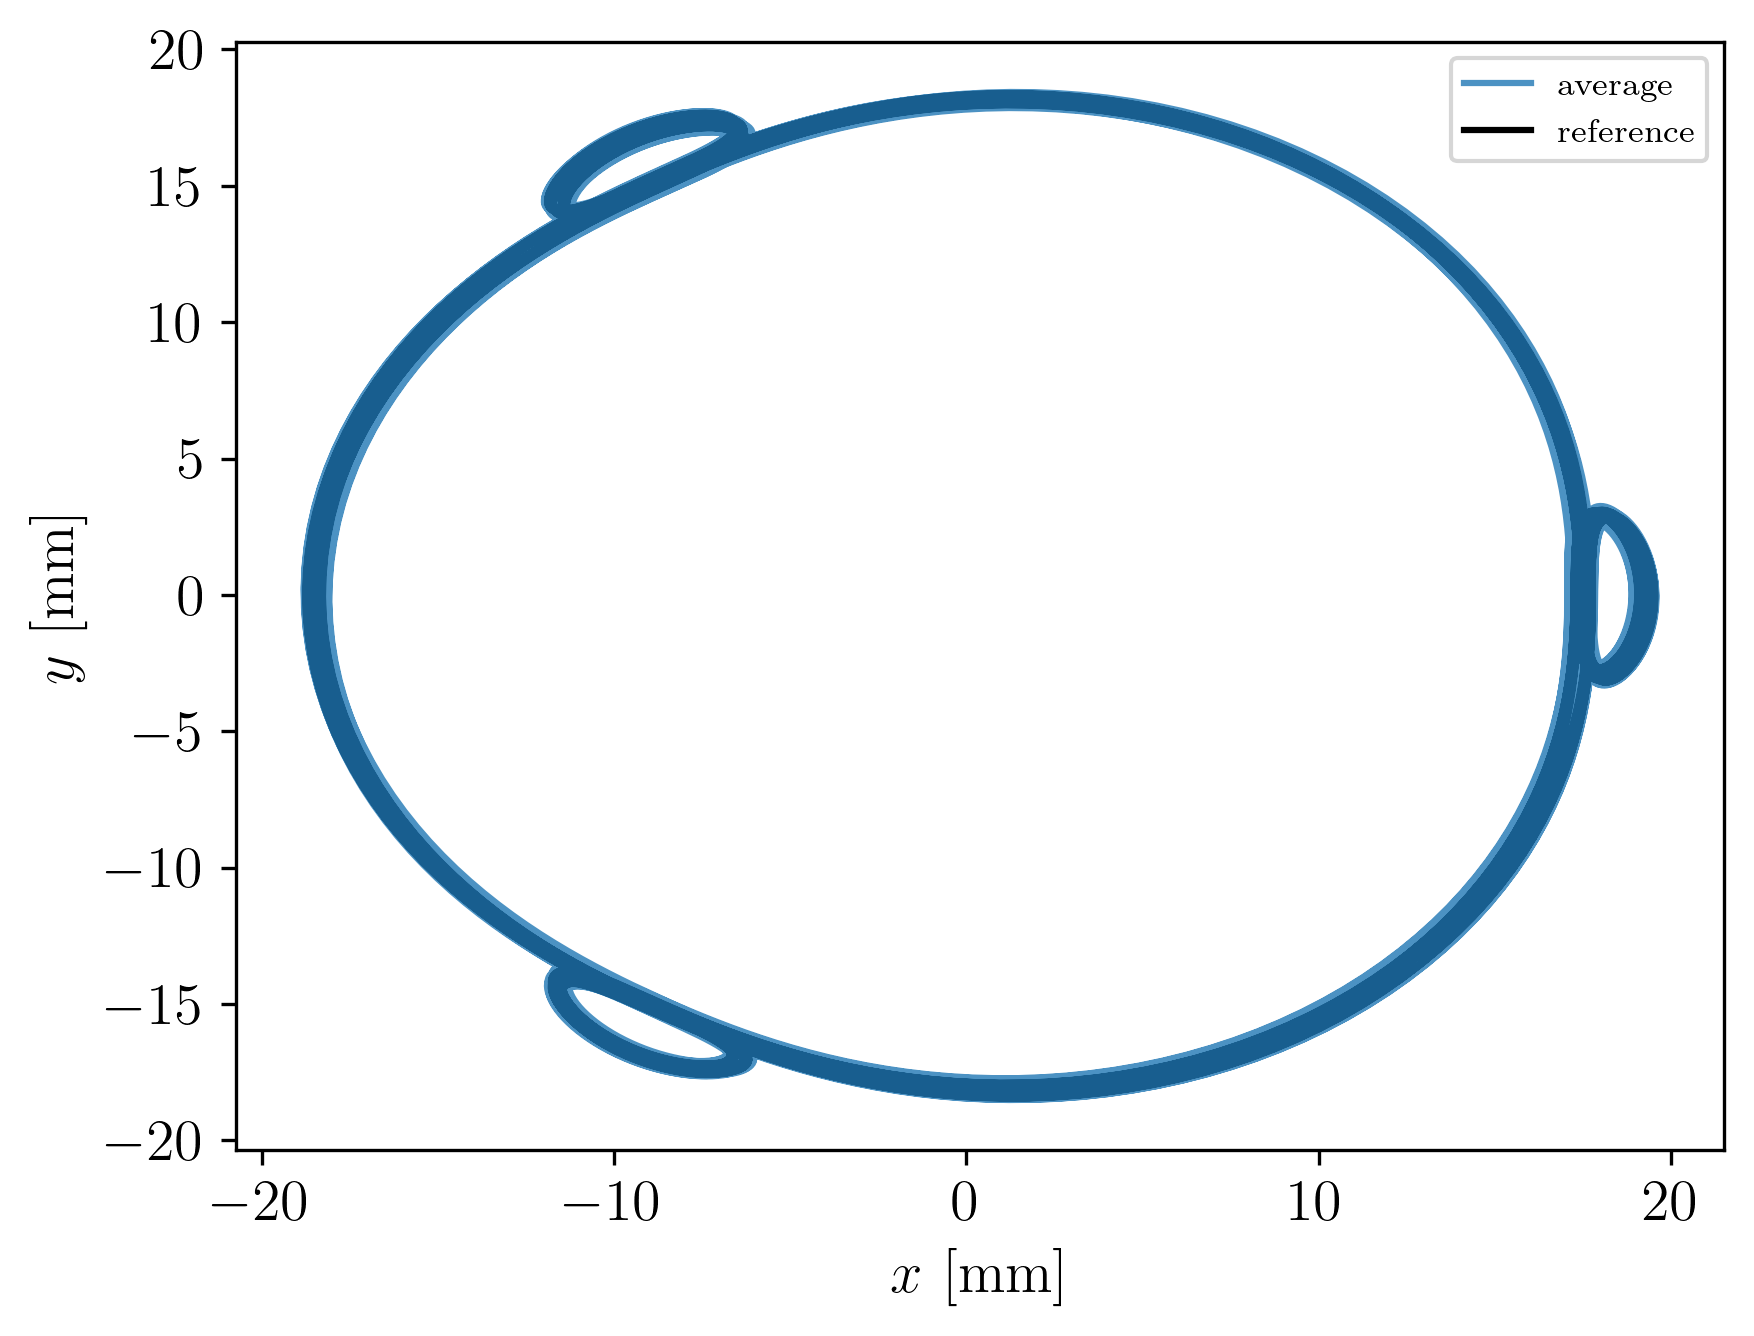

In [20]:
plt.plot(xs3, ys3, alpha=0.8, label='average')
plt.plot(data_ref3['x'].values,data_ref3['y'].values,color='black',label='reference', zorder=0)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper right', fontsize=8);

### Single track w/ i.c. of average

In [22]:
data4 = readDetData('zntuple_avg2_2.txt')

In [23]:
data4 = data4[data4['EventID']==1]

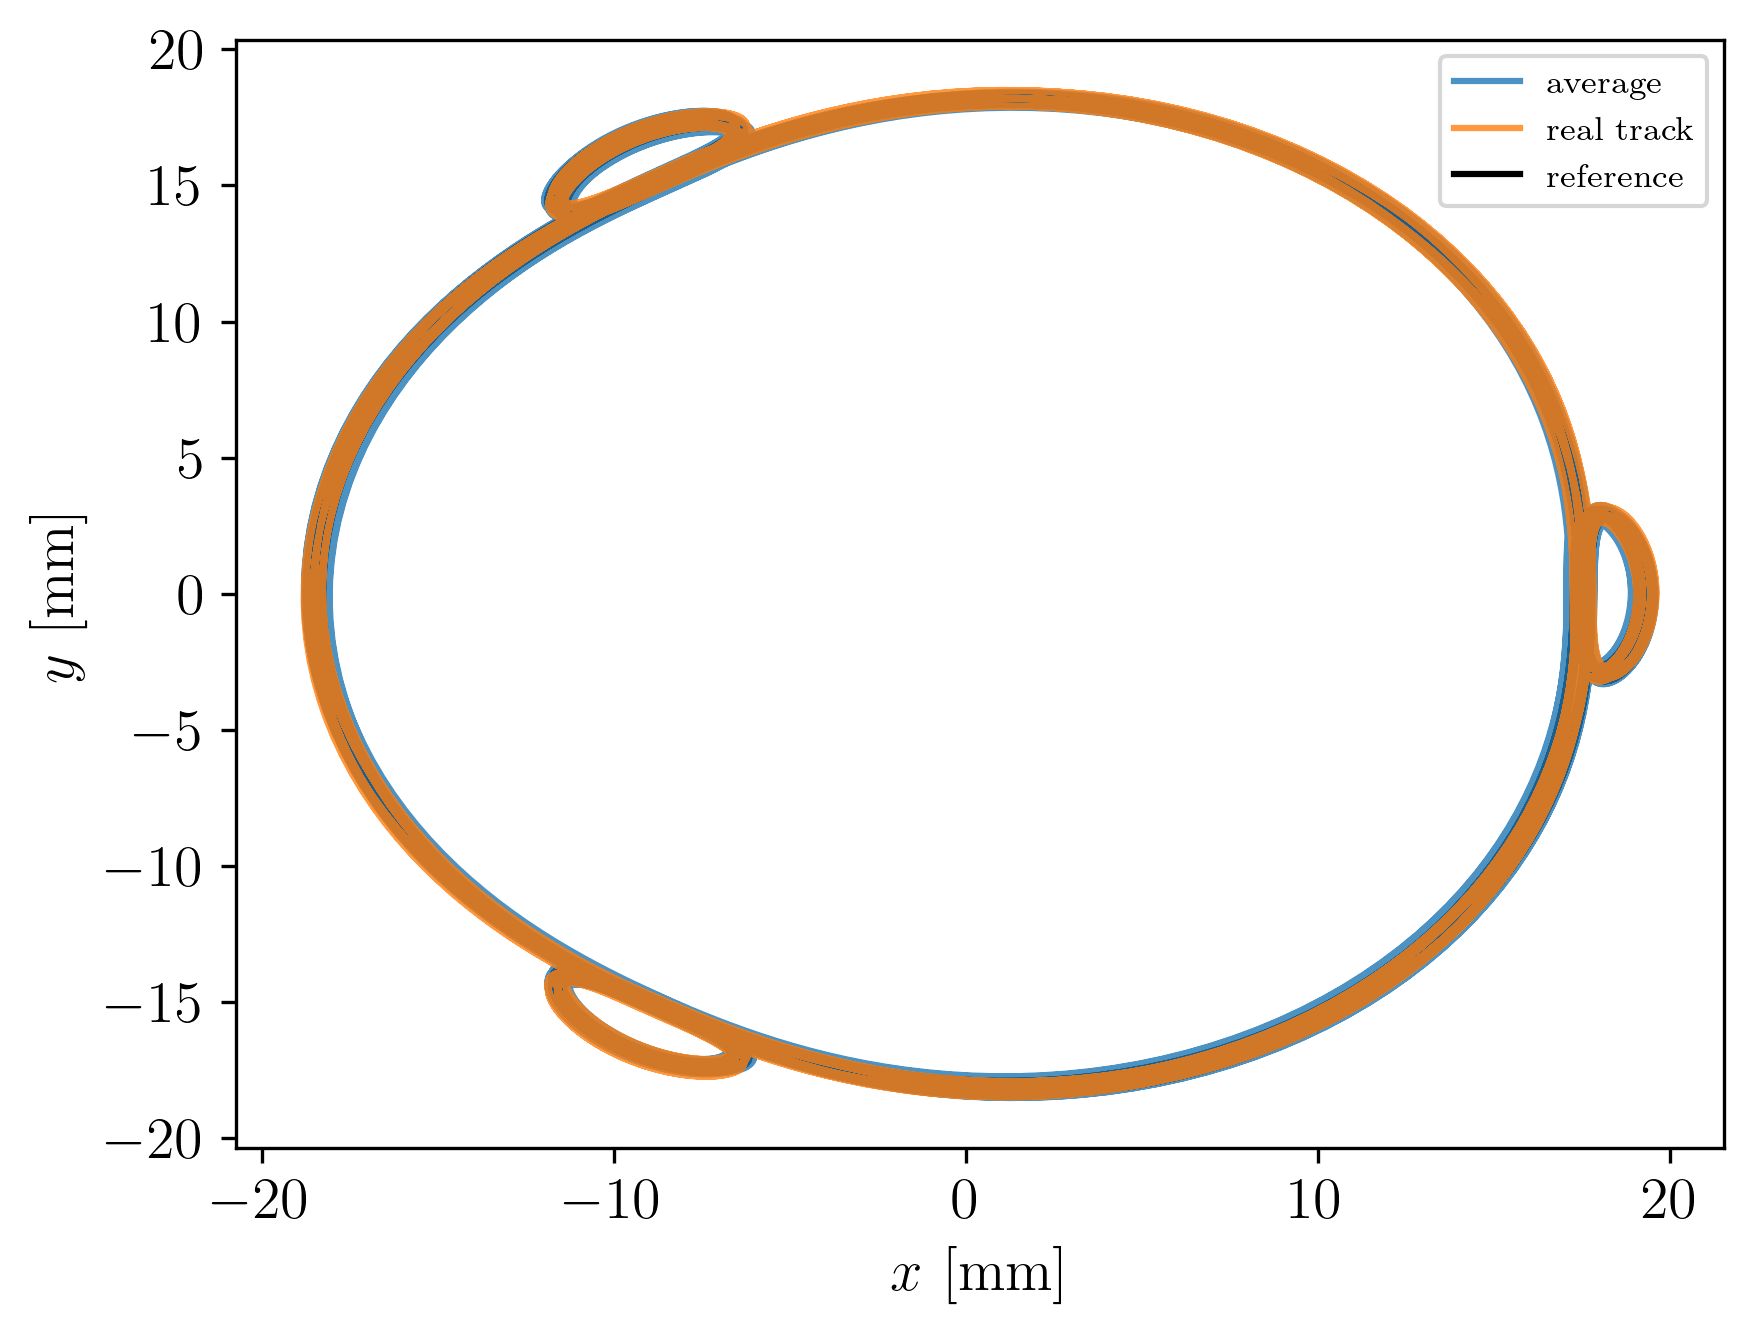

In [25]:
plt.plot(xs3, ys3, alpha=0.8, label='average')
plt.plot(data4['x'], data4['y'], alpha=0.8, label='real track')
plt.plot(data_ref3['x'].values,data_ref3['y'].values,color='black',label='reference', zorder=0)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper right', fontsize=8);

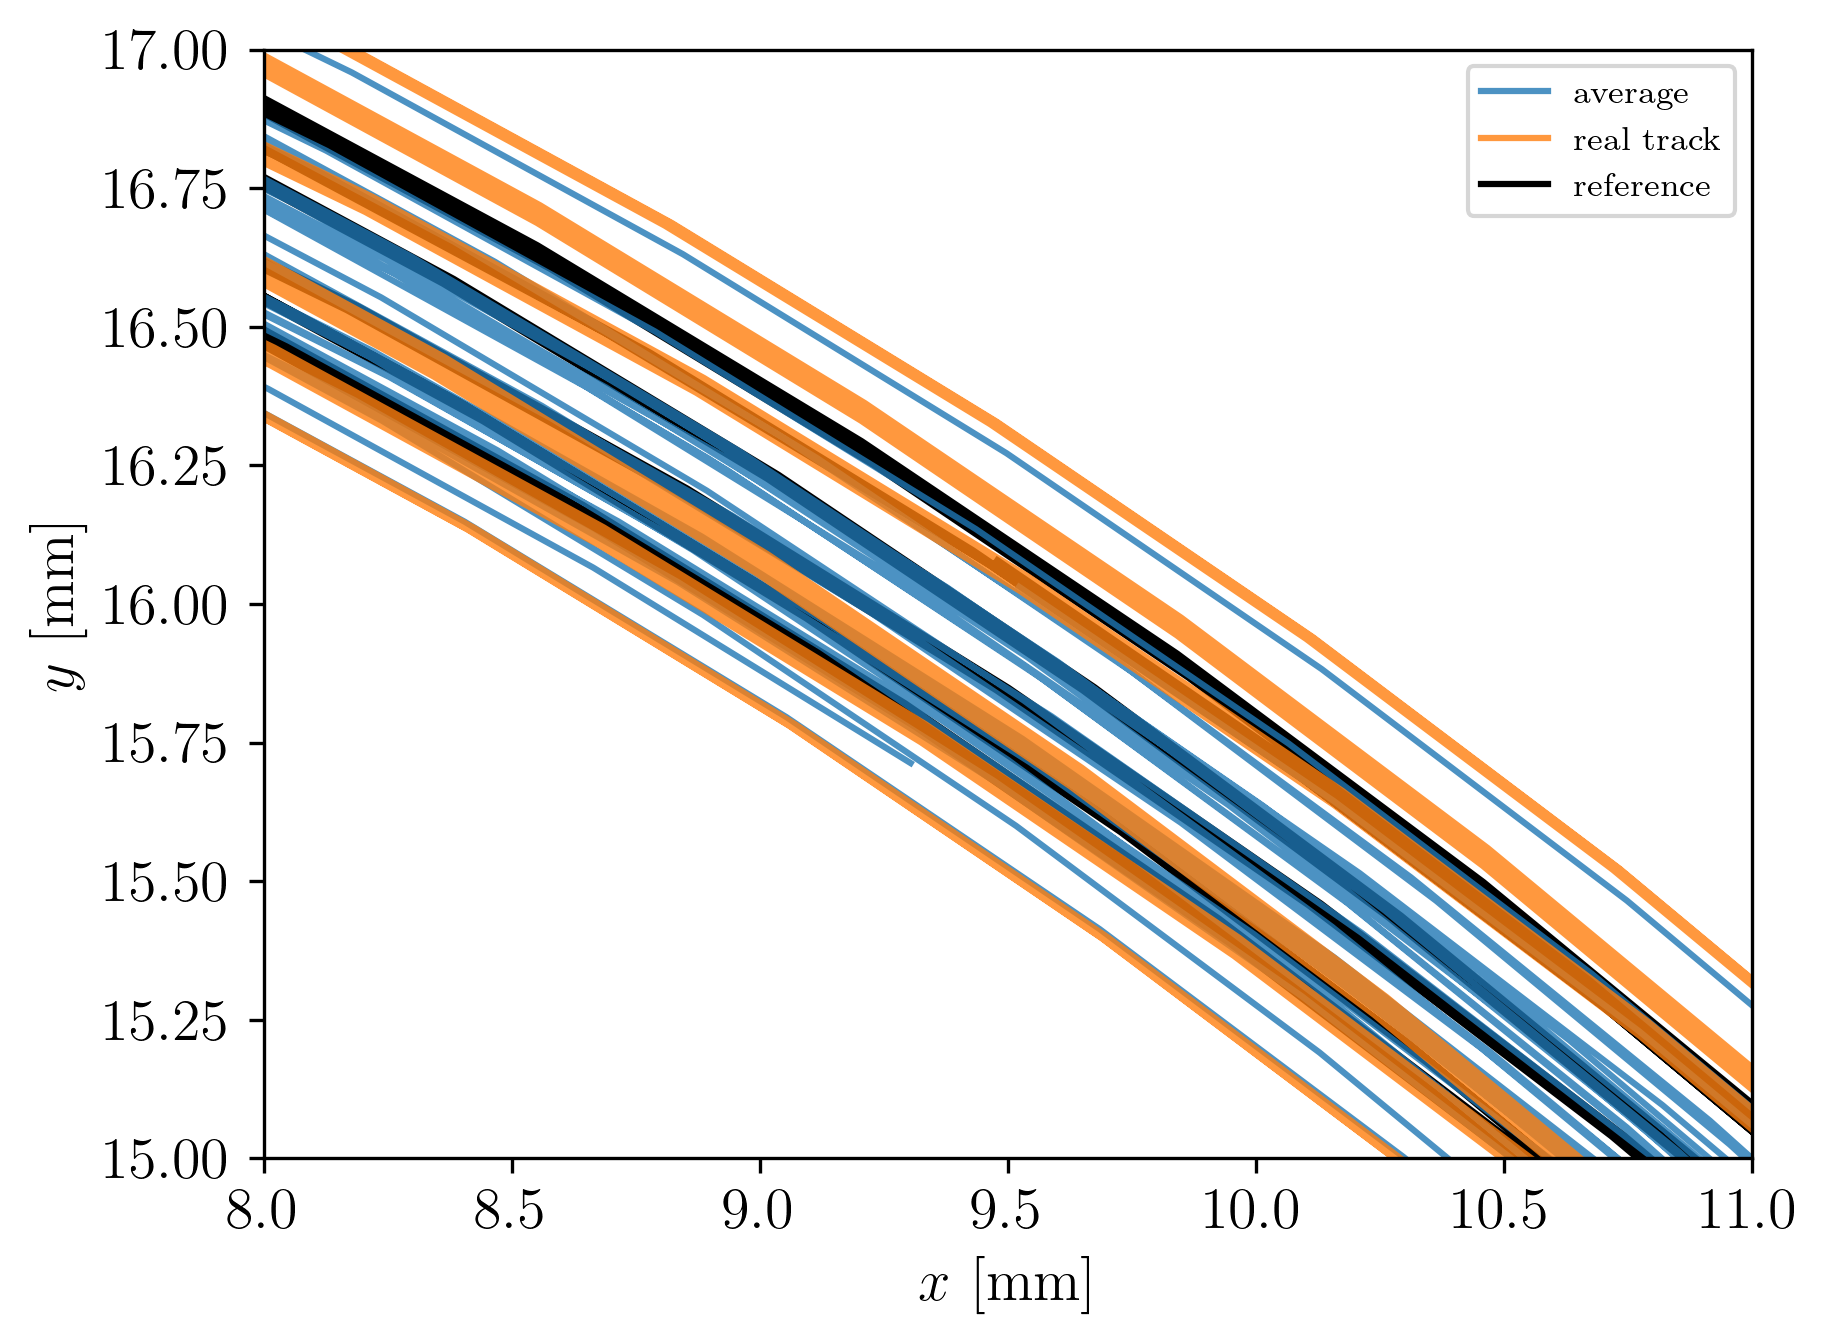

In [30]:
plt.plot(xs3, ys3, alpha=0.8, label='average')
plt.plot(data4['x'], data4['y'], alpha=0.8, label='real track')
plt.plot(data_ref3['x'].values,data_ref3['y'].values,color='black',label='reference', zorder=0)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim(8,11)
plt.ylim(15,17)
plt.legend(loc='upper right', fontsize=8);

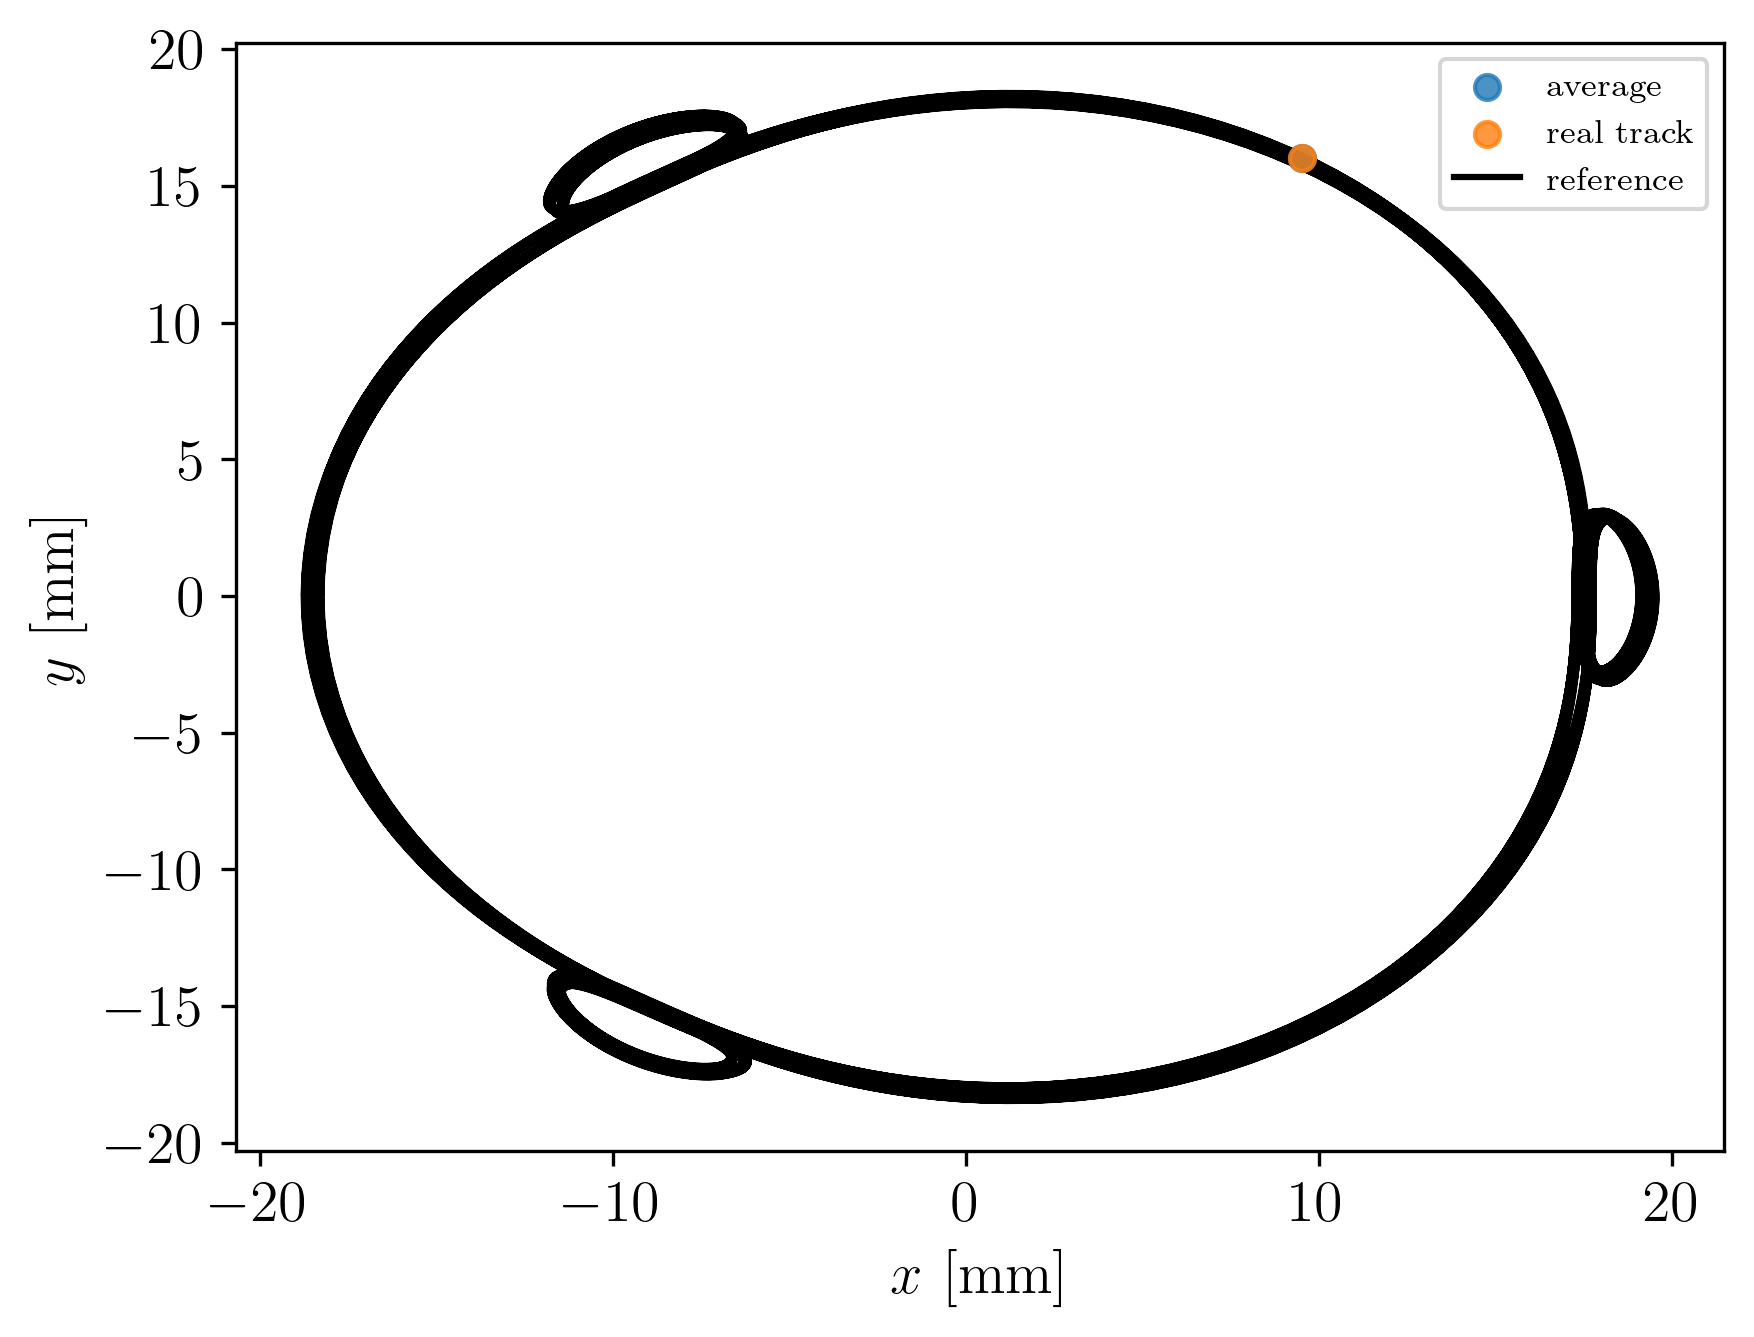

In [26]:
plt.scatter(xs3[0], ys3[0], alpha=0.8, label='average')
plt.scatter(data4['x'].values[0], data4['y'].values[0], alpha=0.8, label='real track')
plt.plot(data_ref3['x'].values,data_ref3['y'].values,color='black',label='reference', zorder=0)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.legend(loc='upper right', fontsize=8);

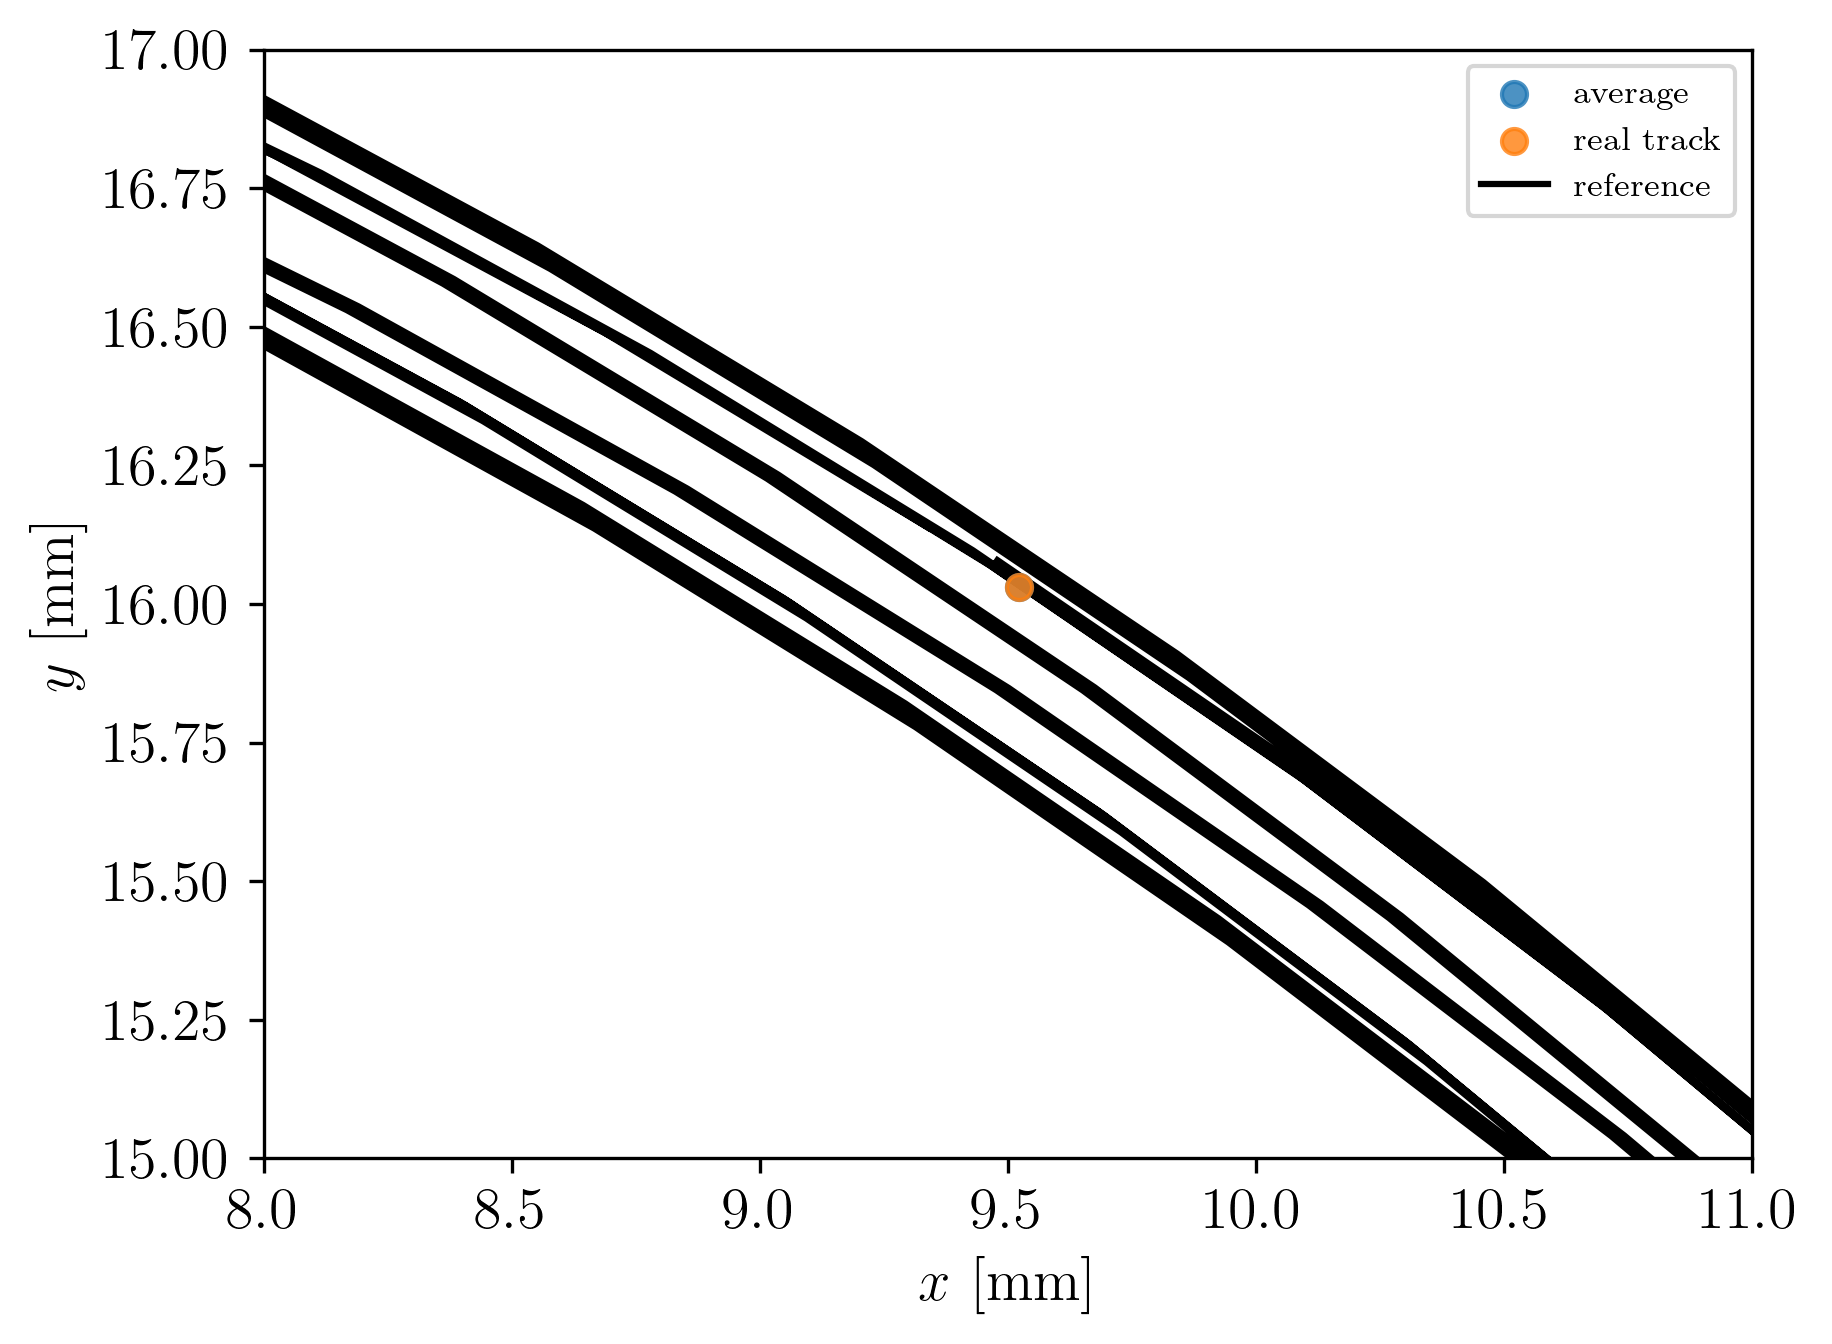

In [29]:
plt.scatter(xs3[0], ys3[0], alpha=0.8, label='average')
plt.scatter(data4['x'].values[0], data4['y'].values[0], alpha=0.8, label='real track')
plt.plot(data_ref3['x'].values,data_ref3['y'].values,color='black',label='reference', zorder=0)
plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.xlim(8,11)
plt.ylim(15,17)
plt.legend(loc='upper right', fontsize=8);

Larry suggests we are approaching the regime of numerical noise here. what happens if we reduce the max step size?

--> TODO: re-do these plots w/ maxStep=0.1mm